# Лабораторная работа №2 по курсу «Системы искусственного интеллекта»
## Тема: «Продукционная модель представления знаний и механизмы логического вывода»
### Вариант №8: «Отбор кандидатов на вакантное место»

**Цель работы:** реализовать пополняемую динамическую базу знаний продукционного типа, которая не входит в текст интерпретатора. Механизм вывода — обратный (Backward Chaining), язык — исчисление предикатов первого порядка, представление — граф И/ИЛИ, есть разрешение конфликтов и объяснения «ПОЧЕМУ?» и «КАК?».

Ноутбук самодостаточный: интерпретатор, база правил и факты находятся в ячейках ниже. Интерпретатор читает правила и факты из JSON-файлов, которые ноутбук записывает на диск перед запуском. Добавление правила или факта не требует правки кода вывода.


---
## 1. Импорт библиотек

In [9]:
import json
import os
from typing import Any, Dict, List, Optional, Set, Tuple, Union

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["axes.unicode_minus"] = False

---
## 2. Предметная область

Вариант 8 — отбор кандидата на IT-вакансию. Чётный номер варианта задаёт обратный вывод: поиск идёт от целевой гипотезы к фактам.

Признаки кандидата: образование, первичный скрининг, опыт, результат технического интервью, командная работа, коммуникация, английский, международные проекты.

Целевые гипотезы предиката `рекомендация_кандидату`:
1. `принять_senior`
2. `принять_middle`
3. `испытательный_срок`
4. `кадровый_резерв`
5. `отказ`

---
## 3. Интерпретатор обратного вывода

In [12]:
"""
Модуль продукционной экспертной системы обратного вывода с исчислением предикатов первого порядка.
Вариант №8: Отбор кандидатов на вакантное место.
"""

from typing import List, Dict, Any, Optional, Tuple, Set, Union
import json
import os

class Term:
    def __init__(self, value: str, is_var: bool = False):
        self.value = value
        self.is_var = is_var or value.startswith("?")

    def __repr__(self):
        return self.value

    def __eq__(self, other):
        if isinstance(other, Term):
            return self.value == other.value and self.is_var == other.is_var
        return False

    def __hash__(self):
        return hash((self.value, self.is_var))


class Predicate:
    def __init__(self, name: str, args: List[Union[str, Term]]):
        self.name = name
        self.args: List[Term] = [
            arg if isinstance(arg, Term) else Term(arg)
            for arg in args
        ]

    def substitute(self, bindings: Dict[str, str]) -> 'Predicate':
        new_args = []
        for a in self.args:
            if a.is_var and a.value in bindings:
                new_args.append(Term(bindings[a.value], is_var=False))
            else:
                new_args.append(Term(a.value, is_var=a.is_var))
        return Predicate(self.name, new_args)

    def match(self, ground: 'Predicate') -> Optional[Dict[str, str]]:
        if self.name != ground.name or len(self.args) != len(ground.args):
            return None
        bindings = {}
        for pat_arg, g_arg in zip(self.args, ground.args):
            if pat_arg.is_var:
                if pat_arg.value in bindings:
                    if bindings[pat_arg.value] != g_arg.value:
                        return None
                else:
                    bindings[pat_arg.value] = g_arg.value
            else:
                if pat_arg.value != g_arg.value:
                    return None
        return bindings

    def is_ground(self) -> bool:
        return all(not a.is_var for a in self.args)

    def to_string(self) -> str:
        args_str = ", ".join(a.value for a in self.args)
        return f"{self.name}({args_str})"

    def __repr__(self):
        return self.to_string()

    def __eq__(self, other):
        if isinstance(other, Predicate):
            return self.name == other.name and [a.value for a in self.args] == [a.value for a in other.args]
        return False

    def __hash__(self):
        return hash((self.name, tuple(a.value for a in self.args)))


class Rule:
    def __init__(
        self,
        rule_id: str,
        name: str,
        premises: Dict[str, Any],
        conclusion: Union[Predicate, Dict[str, Any]],
        priority: int = 10,
        author: str = "HR_Expert"
    ):
        self.id = rule_id
        self.name = name
        self.premises = premises  # {'and': [Predicate, ...]} or {'or': [...]}
        if isinstance(conclusion, Predicate):
            self.conclusion = conclusion
        else:
            self.conclusion = Predicate(conclusion['pred'], conclusion['args'])
        self.priority = priority
        self.author = author

    def get_premises_list(self) -> List[Predicate]:
        if 'and' in self.premises:
            return [p if isinstance(p, Predicate) else Predicate(p['pred'], p['args']) for p in self.premises['and']]
        elif 'or' in self.premises:
            return [p if isinstance(p, Predicate) else Predicate(p['pred'], p['args']) for p in self.premises['or']]
        return []

    def __repr__(self):
        prem_type = " AND " if 'and' in self.premises else " OR "
        prems = prem_type.join(str(p) for p in self.get_premises_list())
        return f"[{self.id}] IF {prems} THEN {self.conclusion} (Priority: {self.priority})"


class ProofNode:
    def __init__(
        self,
        goal: Predicate,
        rule: Optional[Rule] = None,
        success: bool = False,
        children: Optional[List['ProofNode']] = None,
        is_fact: bool = False,
        explanation_step: int = 0,
        failed_condition: Optional[str] = None
    ):
        self.goal = goal
        self.rule = rule
        self.success = success
        self.children: List['ProofNode'] = children or []
        self.is_fact = is_fact
        self.step = explanation_step
        self.failed_condition = failed_condition

    def add_child(self, child: 'ProofNode'):
        self.children.append(child)


class BackwardChainingEngine:
    def __init__(self, conflict_resolution_strategy: str = "priority_first"):
        self.rules: List[Rule] = []
        self.working_memory: Set[Predicate] = set()
        self.conflict_resolution_strategy = conflict_resolution_strategy
        self.derivation_log: List[str] = []
        self.explanation_steps: List[Dict[str, Any]] = []
        self.step_counter = 0

    def load_rules_from_file(self, filepath: str):
        with open(filepath, 'r', encoding='utf-8') as f:
            data = json.load(f)
            self.rules = []
            for r_data in data['rules']:
                conclusion = Predicate(r_data['conclusion']['pred'], r_data['conclusion']['args'])
                premises = {}
                for k, v in r_data['premises'].items():
                    premises[k] = [Predicate(p['pred'], p['args']) for p in v]
                rule = Rule(
                    rule_id=r_data['id'],
                    name=r_data.get('name', ''),
                    premises=premises,
                    conclusion=conclusion,
                    priority=r_data.get('priority', 10)
                )
                self.rules.append(rule)
        self.derivation_log.append(f"Загружено {len(self.rules)} правил из файла {filepath}.")

    def load_facts_from_file(self, filepath: str, candidate_name: Optional[str] = None):
        with open(filepath, 'r', encoding='utf-8') as f:
            data = json.load(f)
            self.working_memory.clear()
            candidates = data.get('candidates', {})
            if candidate_name and candidate_name in candidates:
                for f_data in candidates[candidate_name]:
                    self.working_memory.add(Predicate(f_data['pred'], f_data['args']))
                self.derivation_log.append(
                    f"Загружено {len(self.working_memory)} фактов для кандидата '{candidate_name}'."
                )
            elif candidate_name:
                raise ValueError(f"Кандидат {candidate_name} не найден в базе фактов.")
            else:
                first_cand = next(iter(candidates))
                for f_data in candidates[first_cand]:
                    self.working_memory.add(Predicate(f_data['pred'], f_data['args']))
                self.derivation_log.append(
                    f"Загружены факты первого кандидата '{first_cand}' ({len(self.working_memory)} шт.)."
                )

    def add_fact(self, fact: Predicate):
        self.working_memory.add(fact)
        self.derivation_log.append(f"[ПОПОЛНЕНИЕ РП] Добавлен факт: {fact.to_string()}")

    def add_rule(self, rule: Rule):
        # Проверка на дубликат по id
        self.rules = [r for r in self.rules if r.id != rule.id]
        self.rules.append(rule)
        self.derivation_log.append(f"[ПОПОЛНЕНИЕ БЗ] Добавлено правило [{rule.id}]: {rule.name}")

    def save_rules_to_file(self, filepath: str):
        rules_data = []
        for r in self.rules:
            prem_dict = {}
            if 'and' in r.premises:
                prem_dict['and'] = [
                    {"pred": p.name, "args": [a.value for a in p.args]}
                    for p in r.get_premises_list()
                ]
            else:
                prem_dict['or'] = [
                    {"pred": p.name, "args": [a.value for a in p.args]}
                    for p in r.get_premises_list()
                ]
            rules_data.append({
                "id": r.id,
                "name": r.name,
                "priority": r.priority,
                "premises": prem_dict,
                "conclusion": {
                    "pred": r.conclusion.name,
                    "args": [a.value for a in r.conclusion.args]
                }
            })
        with open(filepath, 'w', encoding='utf-8') as f:
            json.dump({"rules": rules_data}, f, ensure_ascii=False, indent=2)
        self.derivation_log.append(f"[ЭКСПОРТ БЗ] База правил сохранена в файл {filepath}")

    def save_facts_to_file(self, filepath: str, candidate_name: str):
        data = {}
        if os.path.exists(filepath):
            with open(filepath, 'r', encoding='utf-8') as f:
                try:
                    data = json.load(f)
                except Exception:
                    data = {}
        if "candidates" not in data:
            data["candidates"] = {}

        candidate_facts = []
        for f in self.working_memory:
            candidate_facts.append({
                "pred": f.name,
                "args": [a.value for a in f.args]
            })
        data["candidates"][candidate_name] = candidate_facts

        with open(filepath, 'w', encoding='utf-8') as f:
            json.dump(data, f, ensure_ascii=False, indent=2)
        self.derivation_log.append(f"[ЭКСПОРТ РП] Факты кандидата {candidate_name} сохранены в {filepath}")

    def resolve_conflict(self, candidate_rules: List[Rule]) -> List[Rule]:
        if self.conflict_resolution_strategy == "priority_first":
            # Сортировка: максимальный приоритет -> наибольшая специфичность (число посылок) -> исходный порядок
            return sorted(
                candidate_rules,
                key=lambda r: (r.priority, len(r.get_premises_list())),
                reverse=True
            )
        elif self.conflict_resolution_strategy == "specificity_first":
            return sorted(
                candidate_rules,
                key=lambda r: (len(r.get_premises_list()), r.priority),
                reverse=True
            )
        return candidate_rules

    def prove_goal(
        self,
        goal: Predicate,
        call_depth: int = 0,
        visited_goals: Optional[Set[str]] = None
    ) -> Tuple[bool, ProofNode]:
        if visited_goals is None:
            visited_goals = set()

        indent = "  " * call_depth
        goal_str = goal.to_string()

        # Защита от зацикливания
        if goal_str in visited_goals:
            self.derivation_log.append(f"{indent}[ЦИКЛ] Повторное обращение к цели {goal_str}, возврат False.")
            return False, ProofNode(goal, success=False, failed_condition="Обнаружен цикл в графе")

        # 1. Проверка рабочей памяти
        for fact in self.working_memory:
            bindings = goal.match(fact)
            if bindings is not None:
                self.step_counter += 1
                self.derivation_log.append(f"{indent}[ФАКТ В БД] Цель {goal_str} подтверждена фактом из РП: {fact}")
                node = ProofNode(goal, success=True, is_fact=True, explanation_step=self.step_counter)
                self.explanation_steps.append({
                    "step": self.step_counter,
                    "type": "fact",
                    "goal": goal_str,
                    "fact": fact.to_string(),
                    "text": f"Утверждение {goal_str} является исходным фактом в базе данных."
                })
                return True, node

        # 2. Поиск правил, заключение которых унифицируется с целью
        matching_rules: List[Tuple[Rule, Dict[str, str]]] = []
        for rule in self.rules:
            bindings = rule.conclusion.match(goal)
            if bindings is not None:
                matching_rules.append((rule, bindings))

        if not matching_rules:
            self.derivation_log.append(f"{indent}[НЕУДАЧА] Для цели {goal_str} нет правил в БЗ и факта в РП.")
            return False, ProofNode(goal, success=False, failed_condition=f"Отсутствует факт/правило для {goal_str}")

        # 3. Разрешение конфликта: сортировка правил
        candidate_rules = [r for r, _ in matching_rules]
        ordered_rules = self.resolve_conflict(candidate_rules)
        rule_bindings = {r.id: b for r, b in matching_rules}

        self.derivation_log.append(
            f"{indent}[КОНФЛИКТНЫЙ НАБОР] Для {goal_str} найдено {len(ordered_rules)} правил: "
            f"{[r.id for r in ordered_rules]} (порядок после разрешения конфликта: {self.conflict_resolution_strategy})"
        )

        visited_goals.add(goal_str)

        # 4. Проверка правил по порядку
        for rule in ordered_rules:
            b = rule_bindings[rule.id]
            self.derivation_log.append(f"{indent}[ПРОБА] Правило {rule.id} (Приоритет {rule.priority}): {rule.name}")
            node = ProofNode(goal, rule=rule, success=False)
            rule_success = True
            failed_cond = None

            is_and = 'and' in rule.premises
            prems = rule.get_premises_list()

            if is_and:
                # Все посылки должны быть доказаны (AND)
                for prem in prems:
                    sub_prem = prem.substitute(b)
                    sub_success, sub_node = self.prove_goal(sub_prem, call_depth + 1, visited_goals.copy())
                    node.add_child(sub_node)
                    if not sub_success:
                        rule_success = False
                        failed_cond = sub_prem.to_string()
                        self.derivation_log.append(
                            f"{indent}  [ОТКЛОНЕНО] Правило {rule.id}: не выполнено условие {failed_cond}"
                        )
                        break
            else:
                # Хотя бы одна посылка (OR)
                or_success = False
                for prem in prems:
                    sub_prem = prem.substitute(b)
                    sub_success, sub_node = self.prove_goal(sub_prem, call_depth + 1, visited_goals.copy())
                    node.add_child(sub_node)
                    if sub_success:
                        or_success = True
                        break
                rule_success = or_success
                if not rule_success:
                    failed_cond = "Ни одно из альтернативных условий OR не выполнено"

            if rule_success:
                self.step_counter += 1
                node.success = True
                node.step = self.step_counter
                self.derivation_log.append(
                    f"{indent}[УСПЕХ] Цель {goal_str} выведена с помощью правила {rule.id}!"
                )
                self.working_memory.add(goal)
                self.explanation_steps.append({
                    "step": self.step_counter,
                    "type": "rule",
                    "goal": goal_str,
                    "rule_id": rule.id,
                    "rule_name": rule.name,
                    "premises": [p.substitute(b).to_string() for p in prems],
                    "text": f"Утверждение {goal_str} доказано по правилу {rule.id} ({rule.name})."
                })
                visited_goals.remove(goal_str)
                return True, node
            else:
                node.failed_condition = failed_cond

        visited_goals.remove(goal_str)
        return False, ProofNode(goal, success=False, failed_condition=f"Не удалось доказать ни одно правило для {goal_str}")

    def explain_why(self, question_premise: str) -> str:
        for r in self.rules:
            for p in r.get_premises_list():
                if p.name in question_premise or question_premise in p.name:
                    return (
                        f"Вопрос о '{question_premise}' необходим для проверки условия правила [{r.id}]: '{r.name}',\n"
                        f"чтобы сделать вывод о заключении: '{r.conclusion.to_string()}'."
                    )
        return f"Условие '{question_premise}' является частью гипотезы текущего логического вывода."

    def explain_how(self, goal_str: str) -> str:
        for item in reversed(self.explanation_steps):
            if goal_str in item['goal']:
                if item['type'] == 'fact':
                    return f"Утверждение '{goal_str}' является исходным фактом в рабочей памяти кандидата."
                elif item['type'] == 'rule':
                    prems_str = "\n  - ".join(item['premises'])
                    return (
                        f"Утверждение '{goal_str}' выведено по правилу [{item['rule_id']}]:\n"
                        f"Название: {item['rule_name']}\n"
                        f"Были подтверждены все посылки:\n  - {prems_str}"
                    )
        return f"Утверждение '{goal_str}' не найдено среди успешно доказанных шагов вывода."


---
## 4. Построение графа И/ИЛИ


In [13]:
def build_full_and_or_graph(engine):
    G = nx.DiGraph()
    for rule in engine.rules:
        r_node = f"[{rule.id}]"
        G.add_node(r_node, type="rule", label=f"{rule.id}\np={rule.priority}")
        c_node = rule.conclusion.to_string()
        G.add_node(c_node, type="fact", label=c_node)
        G.add_edge(r_node, c_node)
        for p in rule.get_premises_list():
            p_node = p.to_string()
            G.add_node(p_node, type="fact", label=p_node)
            G.add_edge(p_node, r_node)
    return G


def plot_and_or_graph(G, title="Граф И/ИЛИ базы знаний (вариант 8)"):
    plt.figure(figsize=(16, 10))
    rule_nodes = [n for n, d in G.nodes(data=True) if d.get("type") == "rule"]
    fact_nodes = [n for n, d in G.nodes(data=True) if d.get("type") == "fact"]
    pos = nx.spring_layout(G, k=0.55, iterations=80, seed=42)
    nx.draw_networkx_nodes(G, pos, nodelist=fact_nodes, node_color="#A0CBE8",
                           node_shape="o", node_size=900, edgecolors="#1F77B4")
    nx.draw_networkx_nodes(G, pos, nodelist=rule_nodes, node_color="#FFBE7D",
                           node_shape="s", node_size=700, edgecolors="#D95F02")
    nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=12, edge_color="#555555")
    labels = {n: G.nodes[n].get("label", n) for n in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=6)
    plt.title(title, fontsize=13, fontweight="bold")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


def plot_partial_proof_graph(engine, candidate_name, goal):
    G = nx.DiGraph()
    for step in engine.explanation_steps:
        if step["type"] == "rule":
            r_node = f"[{step['rule_id']}]"
            g_node = step["goal"]
            G.add_node(r_node, type="rule", label=step["rule_id"])
            G.add_node(g_node, type="fact", label=g_node)
            G.add_edge(r_node, g_node)
            for p in step["premises"]:
                G.add_node(p, type="fact", label=p)
                G.add_edge(p, r_node)
        elif step["type"] == "fact":
            G.add_node(step["fact"], type="input_fact", label=step["fact"])
    plt.figure(figsize=(14, 8))
    pos = nx.spring_layout(G, k=0.7, iterations=60, seed=24)
    rule_nodes = [n for n, d in G.nodes(data=True) if d.get("type") == "rule"]
    input_facts = [n for n, d in G.nodes(data=True) if d.get("type") == "input_fact"]
    derived = [n for n, d in G.nodes(data=True) if d.get("type") == "fact" and n not in input_facts]
    if input_facts:
        nx.draw_networkx_nodes(G, pos, nodelist=input_facts, node_color="#86efac",
                               node_shape="o", node_size=1400, edgecolors="#16a34a", label="Факты")
    if derived:
        nx.draw_networkx_nodes(G, pos, nodelist=derived, node_color="#93c5fd",
                               node_shape="o", node_size=1600, edgecolors="#2563eb", label="Вывод")
    if rule_nodes:
        nx.draw_networkx_nodes(G, pos, nodelist=rule_nodes, node_color="#fde047",
                               node_shape="s", node_size=1100, edgecolors="#ca8a04", label="Правила")
    nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=14, edge_color="#334155")
    labels = {n: G.nodes[n].get("label", n) for n in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=7)
    plt.title(f"Частичный граф вывода: {candidate_name}\n{goal.to_string()}", fontsize=12)
    plt.legend(scatterpoints=1, loc="upper left")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


---
## 5. Внешняя база знаний

Правила и факты записаны как данные JSON и сохраняются в файлы `kb/rules.json` и `kb/facts.json`. Интерпретатор получает их только чтением этих файлов.


In [14]:
RULES = {
  "rules": [
    {
      "id": "R1",
      "name": "Допуск кандидата к рассмотрению",
      "priority": 10,
      "premises": {
        "and": [
          {
            "pred": "имеет_высшее_образование",
            "args": [
              "?X",
              "профильное"
            ]
          },
          {
            "pred": "прошел_первичный_скрининг",
            "args": [
              "?X",
              "да"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "допущен_к_отбору",
        "args": [
          "?X",
          "да"
        ]
      }
    },
    {
      "id": "R2_A",
      "name": "Высокий уровень Hard Skills (Senior)",
      "priority": 20,
      "premises": {
        "and": [
          {
            "pred": "опыт_работы_лет",
            "args": [
              "?X",
              "более_5"
            ]
          },
          {
            "pred": "успешное_тех_интервью",
            "args": [
              "?X",
              "отлично"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "уровень_hard_skills",
        "args": [
          "?X",
          "высокий"
        ]
      }
    },
    {
      "id": "R2_B",
      "name": "Высокий уровень Hard Skills (Middle+ с сильной алгоритмической базой)",
      "priority": 15,
      "premises": {
        "and": [
          {
            "pred": "опыт_работы_лет",
            "args": [
              "?X",
              "от_3_до_5"
            ]
          },
          {
            "pred": "успешное_тех_интервью",
            "args": [
              "?X",
              "отлично"
            ]
          },
          {
            "pred": "системное_мышление",
            "args": [
              "?X",
              "высокое"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "уровень_hard_skills",
        "args": [
          "?X",
          "высокий"
        ]
      }
    },
    {
      "id": "R3_A",
      "name": "Средний уровень Hard Skills (опыт 3-5 лет, собеседование хорошо)",
      "priority": 10,
      "premises": {
        "and": [
          {
            "pred": "опыт_работы_лет",
            "args": [
              "?X",
              "от_3_до_5"
            ]
          },
          {
            "pred": "успешное_тех_интервью",
            "args": [
              "?X",
              "хорошо"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "уровень_hard_skills",
        "args": [
          "?X",
          "средний"
        ]
      }
    },
    {
      "id": "R3_B",
      "name": "Средний уровень Hard Skills (быстрый старт: до 3 лет, собеседование отлично)",
      "priority": 8,
      "premises": {
        "and": [
          {
            "pred": "опыт_работы_лет",
            "args": [
              "?X",
              "до_3"
            ]
          },
          {
            "pred": "успешное_тех_интервью",
            "args": [
              "?X",
              "отлично"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "уровень_hard_skills",
        "args": [
          "?X",
          "средний"
        ]
      }
    },
    {
      "id": "R3_C",
      "name": "Базовый уровень Hard Skills (Junior: до 3 лет, собеседование хорошо)",
      "priority": 6,
      "premises": {
        "and": [
          {
            "pred": "опыт_работы_лет",
            "args": [
              "?X",
              "до_3"
            ]
          },
          {
            "pred": "успешное_тех_интервью",
            "args": [
              "?X",
              "хорошо"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "уровень_hard_skills",
        "args": [
          "?X",
          "базовый"
        ]
      }
    },
    {
      "id": "R4",
      "name": "Высокий уровень Soft Skills",
      "priority": 15,
      "premises": {
        "and": [
          {
            "pred": "командная_работа",
            "args": [
              "?X",
              "высокая"
            ]
          },
          {
            "pred": "навыки_коммуникации",
            "args": [
              "?X",
              "высокие"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "уровень_soft_skills",
        "args": [
          "?X",
          "высокий"
        ]
      }
    },
    {
      "id": "R5",
      "name": "Средний уровень Soft Skills",
      "priority": 10,
      "premises": {
        "and": [
          {
            "pred": "командная_работа",
            "args": [
              "?X",
              "средняя"
            ]
          },
          {
            "pred": "навыки_коммуникации",
            "args": [
              "?X",
              "высокие"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "уровень_soft_skills",
        "args": [
          "?X",
          "средний"
        ]
      }
    },
    {
      "id": "R6",
      "name": "Готовность к международным проектам",
      "priority": 12,
      "premises": {
        "and": [
          {
            "pred": "уровень_английского",
            "args": [
              "?X",
              "b2_или_выше"
            ]
          },
          {
            "pred": "опыт_международных_проектов",
            "args": [
              "?X",
              "да"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "международная_квалификация",
        "args": [
          "?X",
          "подтверждена"
        ]
      }
    },
    {
      "id": "R7",
      "name": "Рекомендация на должность Senior-разработчик / Тимлид",
      "priority": 30,
      "premises": {
        "and": [
          {
            "pred": "допущен_к_отбору",
            "args": [
              "?X",
              "да"
            ]
          },
          {
            "pred": "уровень_hard_skills",
            "args": [
              "?X",
              "высокий"
            ]
          },
          {
            "pred": "уровень_soft_skills",
            "args": [
              "?X",
              "высокий"
            ]
          },
          {
            "pred": "международная_квалификация",
            "args": [
              "?X",
              "подтверждена"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "рекомендация_кандидату",
        "args": [
          "?X",
          "принять_senior"
        ]
      }
    },
    {
      "id": "R8",
      "name": "Рекомендация на должность Middle-разработчик",
      "priority": 25,
      "premises": {
        "and": [
          {
            "pred": "допущен_к_отбору",
            "args": [
              "?X",
              "да"
            ]
          },
          {
            "pred": "уровень_hard_skills",
            "args": [
              "?X",
              "средний"
            ]
          },
          {
            "pred": "уровень_soft_skills",
            "args": [
              "?X",
              "высокий"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "рекомендация_кандидату",
        "args": [
          "?X",
          "принять_middle"
        ]
      }
    },
    {
      "id": "R9",
      "name": "Рекомендация на должность Junior-разработчик / испытательный срок",
      "priority": 20,
      "premises": {
        "and": [
          {
            "pred": "допущен_к_отбору",
            "args": [
              "?X",
              "да"
            ]
          },
          {
            "pred": "уровень_hard_skills",
            "args": [
              "?X",
              "базовый"
            ]
          },
          {
            "pred": "уровень_soft_skills",
            "args": [
              "?X",
              "средний"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "рекомендация_кандидату",
        "args": [
          "?X",
          "испытательный_срок"
        ]
      }
    },
    {
      "id": "R10",
      "name": "Включение в кадровый резерв (сильный технарь со слабым английским)",
      "priority": 15,
      "premises": {
        "and": [
          {
            "pred": "допущен_к_отбору",
            "args": [
              "?X",
              "да"
            ]
          },
          {
            "pred": "уровень_hard_skills",
            "args": [
              "?X",
              "высокий"
            ]
          },
          {
            "pred": "уровень_soft_skills",
            "args": [
              "?X",
              "высокий"
            ]
          },
          {
            "pred": "международная_квалификация",
            "args": [
              "?X",
              "не_подтверждена"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "рекомендация_кандидату",
        "args": [
          "?X",
          "кадровый_резерв"
        ]
      }
    },
    {
      "id": "R11",
      "name": "Отказ кандидату при низком техническом уровне",
      "priority": 40,
      "premises": {
        "and": [
          {
            "pred": "успешное_тех_интервью",
            "args": [
              "?X",
              "неудовлетворительно"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "рекомендация_кандидату",
        "args": [
          "?X",
          "отказ"
        ]
      }
    },
    {
      "id": "R12",
      "name": "Отказ кандидату при непрохождении скрининга",
      "priority": 45,
      "premises": {
        "and": [
          {
            "pred": "прошел_первичный_скрининг",
            "args": [
              "?X",
              "нет"
            ]
          }
        ]
      },
      "conclusion": {
        "pred": "рекомендация_кандидату",
        "args": [
          "?X",
          "отказ"
        ]
      }
    }
  ]
}

FACTS = {
  "candidates": {
    "Иванов": [
      {
        "pred": "имеет_высшее_образование",
        "args": [
          "Иванов",
          "профильное"
        ]
      },
      {
        "pred": "прошел_первичный_скрининг",
        "args": [
          "Иванов",
          "да"
        ]
      },
      {
        "pred": "опыт_работы_лет",
        "args": [
          "Иванов",
          "более_5"
        ]
      },
      {
        "pred": "успешное_тех_интервью",
        "args": [
          "Иванов",
          "отлично"
        ]
      },
      {
        "pred": "командная_работа",
        "args": [
          "Иванов",
          "высокая"
        ]
      },
      {
        "pred": "навыки_коммуникации",
        "args": [
          "Иванов",
          "высокие"
        ]
      },
      {
        "pred": "уровень_английского",
        "args": [
          "Иванов",
          "b2_или_выше"
        ]
      },
      {
        "pred": "опыт_международных_проектов",
        "args": [
          "Иванов",
          "да"
        ]
      }
    ],
    "Петров": [
      {
        "pred": "имеет_высшее_образование",
        "args": [
          "Петров",
          "профильное"
        ]
      },
      {
        "pred": "прошел_первичный_скрининг",
        "args": [
          "Петров",
          "да"
        ]
      },
      {
        "pred": "опыт_работы_лет",
        "args": [
          "Петров",
          "от_3_до_5"
        ]
      },
      {
        "pred": "успешное_тех_интервью",
        "args": [
          "Петров",
          "хорошо"
        ]
      },
      {
        "pred": "командная_работа",
        "args": [
          "Петров",
          "высокая"
        ]
      },
      {
        "pred": "навыки_коммуникации",
        "args": [
          "Петров",
          "высокие"
        ]
      }
    ],
    "Сидоров": [
      {
        "pred": "имеет_высшее_образование",
        "args": [
          "Сидоров",
          "профильное"
        ]
      },
      {
        "pred": "прошел_первичный_скрининг",
        "args": [
          "Сидоров",
          "да"
        ]
      },
      {
        "pred": "опыт_работы_лет",
        "args": [
          "Сидоров",
          "до_3"
        ]
      },
      {
        "pred": "успешное_тех_интервью",
        "args": [
          "Сидоров",
          "хорошо"
        ]
      },
      {
        "pred": "командная_работа",
        "args": [
          "Сидоров",
          "средняя"
        ]
      },
      {
        "pred": "навыки_коммуникации",
        "args": [
          "Сидоров",
          "высокие"
        ]
      }
    ],
    "Кузнецов": [
      {
        "pred": "имеет_высшее_образование",
        "args": [
          "Кузнецов",
          "непрофильное"
        ]
      },
      {
        "pred": "прошел_первичный_скрининг",
        "args": [
          "Кузнецов",
          "нет"
        ]
      },
      {
        "pred": "успешное_тех_интервью",
        "args": [
          "Кузнецов",
          "неудовлетворительно"
        ]
      }
    ]
  }
}

os.makedirs("kb", exist_ok=True)
with open("kb/rules.json", "w", encoding="utf-8") as f:
    json.dump(RULES, f, ensure_ascii=False, indent=2)
with open("kb/facts.json", "w", encoding="utf-8") as f:
    json.dump(FACTS, f, ensure_ascii=False, indent=2)

print("Записано правил:", len(RULES["rules"]))
print("Кандидаты:", ", ".join(FACTS["candidates"]))
print("Файлы: kb/rules.json, kb/facts.json")


Записано правил: 15
Кандидаты: Иванов, Петров, Сидоров, Кузнецов
Файлы: kb/rules.json, kb/facts.json


---
## 6. Полный граф И/ИЛИ

Круги — факты и промежуточные предикаты. Квадраты — правила. Стрелка от посылки к правилу и от правила к заключению.


Вершин: 43, дуг: 50


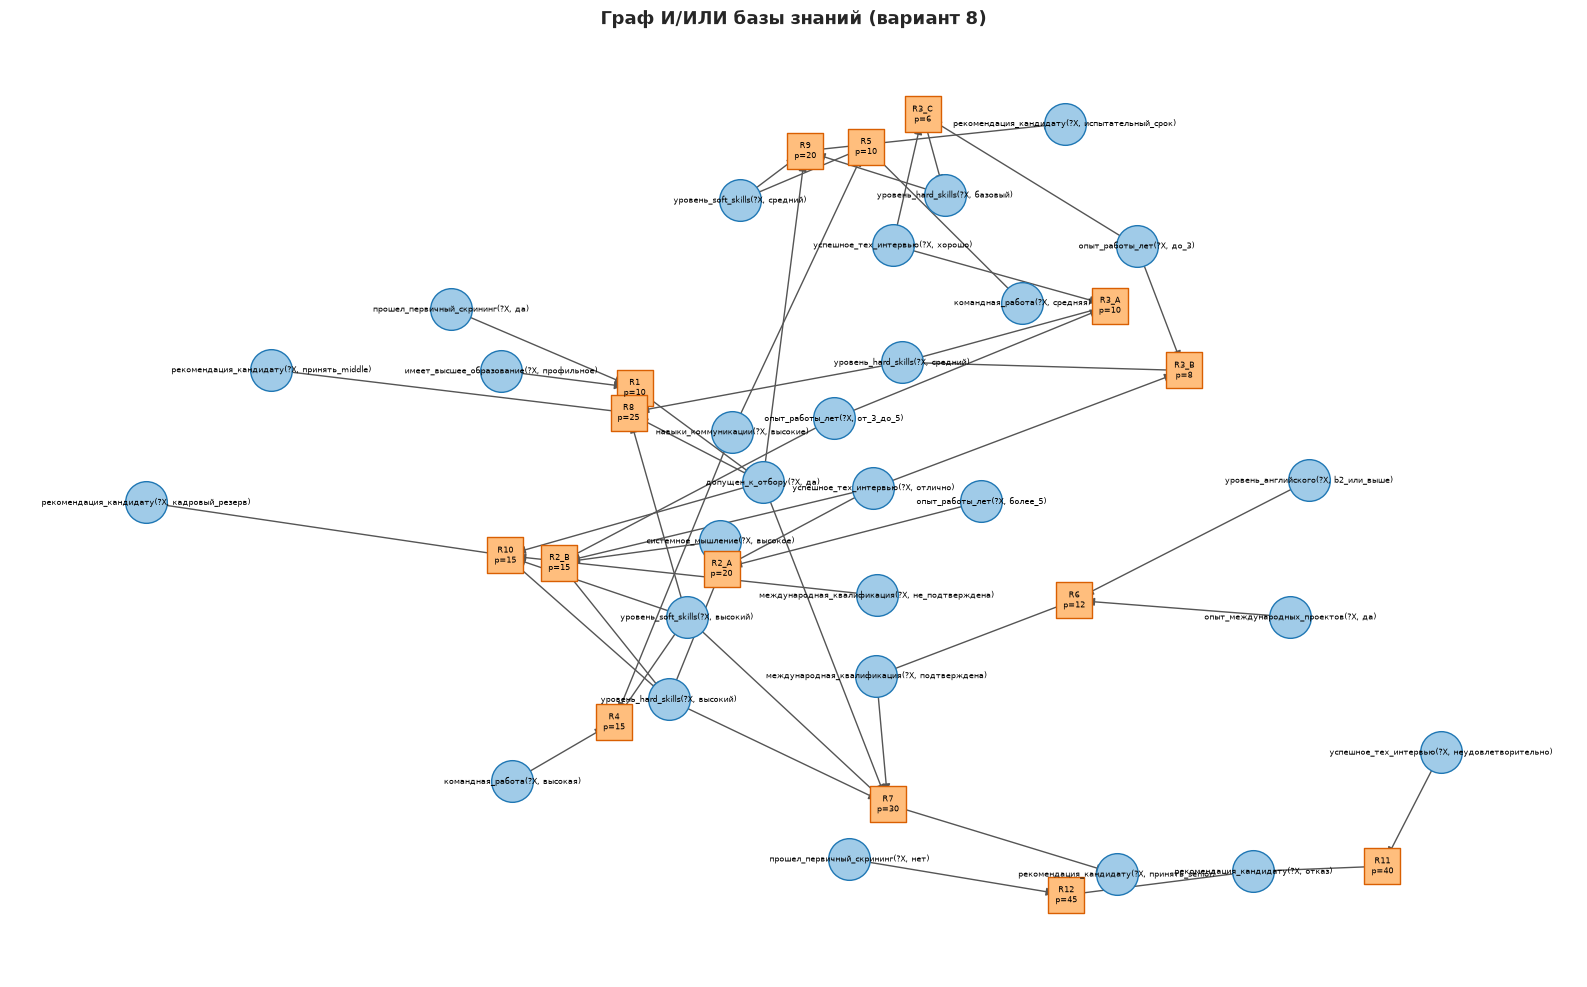

In [15]:
engine = BackwardChainingEngine()
engine.load_rules_from_file("kb/rules.json")
G_full = build_full_and_or_graph(engine)
print(f"Вершин: {G_full.number_of_nodes()}, дуг: {G_full.number_of_edges()}")
plot_and_or_graph(G_full)


---
## 7. Обратный вывод для Иванова

Гипотеза: `рекомендация_кандидату(Иванов, принять_senior)`.


In [16]:
engine_ivanov = BackwardChainingEngine(conflict_resolution_strategy="priority_first")
engine_ivanov.load_rules_from_file("kb/rules.json")
engine_ivanov.load_facts_from_file("kb/facts.json", candidate_name="Иванов")

goal_ivanov = Predicate("рекомендация_кандидату", ["Иванов", "принять_senior"])
success, tree = engine_ivanov.prove_goal(goal_ivanov)
print("Результат:", "УСПЕХ" if success else "НЕУДАЧА")
print()
for line in engine_ivanov.derivation_log:
    print(line)


Результат: УСПЕХ

Загружено 15 правил из файла kb/rules.json.
Загружено 8 фактов для кандидата 'Иванов'.
[КОНФЛИКТНЫЙ НАБОР] Для рекомендация_кандидату(Иванов, принять_senior) найдено 1 правил: ['R7'] (порядок после разрешения конфликта: priority_first)
[ПРОБА] Правило R7 (Приоритет 30): Рекомендация на должность Senior-разработчик / Тимлид
  [КОНФЛИКТНЫЙ НАБОР] Для допущен_к_отбору(Иванов, да) найдено 1 правил: ['R1'] (порядок после разрешения конфликта: priority_first)
  [ПРОБА] Правило R1 (Приоритет 10): Допуск кандидата к рассмотрению
    [ФАКТ В БД] Цель имеет_высшее_образование(Иванов, профильное) подтверждена фактом из РП: имеет_высшее_образование(Иванов, профильное)
    [ФАКТ В БД] Цель прошел_первичный_скрининг(Иванов, да) подтверждена фактом из РП: прошел_первичный_скрининг(Иванов, да)
  [УСПЕХ] Цель допущен_к_отбору(Иванов, да) выведена с помощью правила R1!
  [КОНФЛИКТНЫЙ НАБОР] Для уровень_hard_skills(Иванов, высокий) найдено 2 правил: ['R2_A', 'R2_B'] (порядок после разре

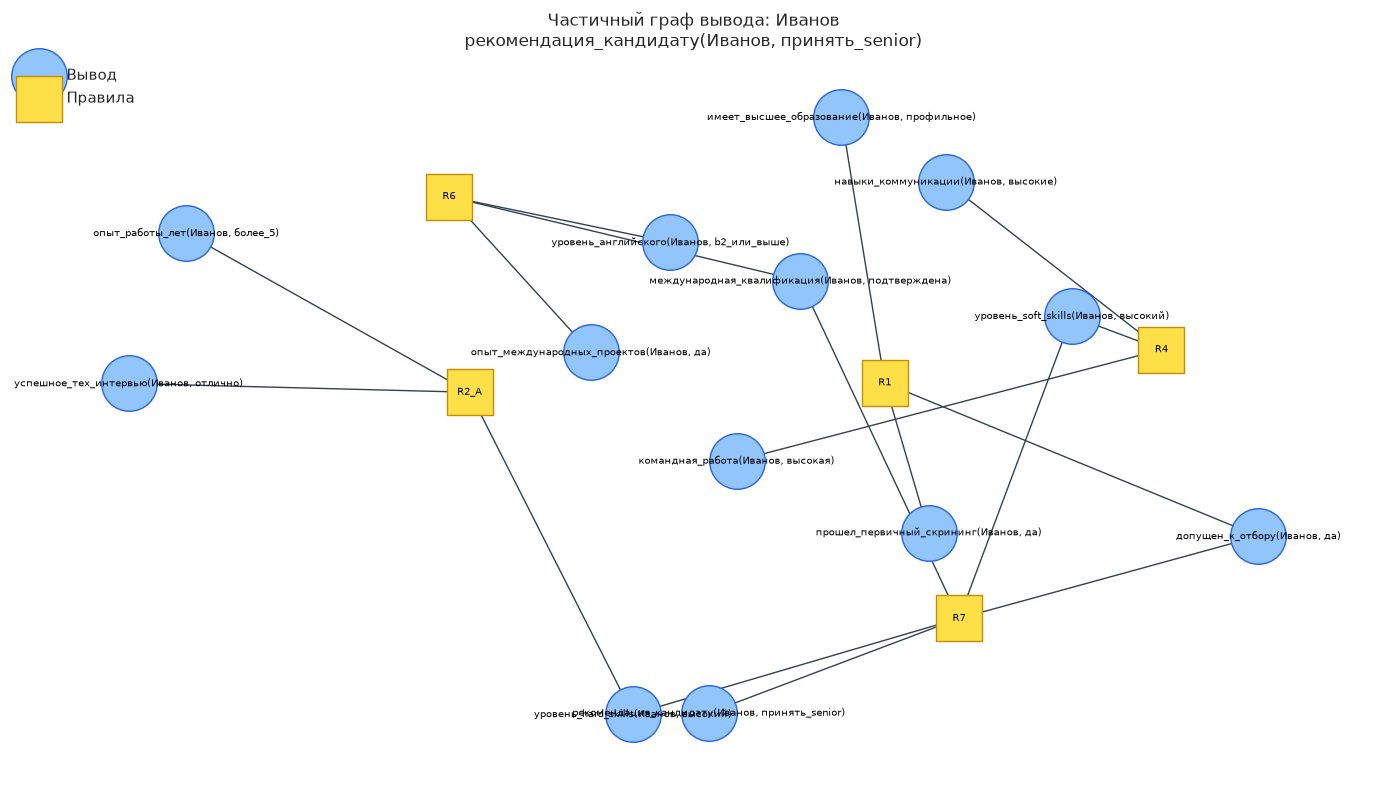

In [17]:
plot_partial_proof_graph(engine_ivanov, "Иванов", goal_ivanov)


---
## 8. Объяснения «КАК?» и «ПОЧЕМУ?»


In [18]:
print("КАК рекомендация_кандидату(Иванов, принять_senior)?")
print(engine_ivanov.explain_how("рекомендация_кандидату(Иванов, принять_senior)"))
print()
print("КАК уровень_hard_skills(Иванов, высокий)?")
print(engine_ivanov.explain_how("уровень_hard_skills(Иванов, высокий)"))
print()
print("ПОЧЕМУ нужен опыт_работы_лет?")
print(engine_ivanov.explain_why("опыт_работы_лет"))


КАК рекомендация_кандидату(Иванов, принять_senior)?
Утверждение 'рекомендация_кандидату(Иванов, принять_senior)' выведено по правилу [R7]:
Название: Рекомендация на должность Senior-разработчик / Тимлид
Были подтверждены все посылки:
  - допущен_к_отбору(Иванов, да)
  - уровень_hard_skills(Иванов, высокий)
  - уровень_soft_skills(Иванов, высокий)
  - международная_квалификация(Иванов, подтверждена)

КАК уровень_hard_skills(Иванов, высокий)?
Утверждение 'уровень_hard_skills(Иванов, высокий)' выведено по правилу [R2_A]:
Название: Высокий уровень Hard Skills (Senior)
Были подтверждены все посылки:
  - опыт_работы_лет(Иванов, более_5)
  - успешное_тех_интервью(Иванов, отлично)

ПОЧЕМУ нужен опыт_работы_лет?
Вопрос о 'опыт_работы_лет' необходим для проверки условия правила [R2_A]: 'Высокий уровень Hard Skills (Senior)',
чтобы сделать вывод о заключении: 'уровень_hard_skills(?X, высокий)'.


---
## 9. Проверка всех кандидатов


In [19]:
candidates = ["Иванов", "Петров", "Сидоров", "Кузнецов"]
hypotheses = ["принять_senior", "принять_middle", "испытательный_срок", "кадровый_резерв", "отказ"]
rows = []
for name in candidates:
    proven = None
    rule_id = None
    steps = 0
    for hyp in hypotheses:
        eng = BackwardChainingEngine()
        eng.load_rules_from_file("kb/rules.json")
        eng.load_facts_from_file("kb/facts.json", candidate_name=name)
        goal = Predicate("рекомендация_кандидату", [name, hyp])
        ok, node = eng.prove_goal(goal)
        if ok:
            proven = hyp
            rule_id = node.rule.id if node.rule else "факт"
            steps = eng.step_counter
            break
    rows.append({
        "Кандидат": name,
        "Решение": proven,
        "Правило": rule_id,
        "Шагов": steps,
    })
display(pd.DataFrame(rows))


,Кандидат,Решение,Правило,Шагов
0,Иванов,принять_senior,R7,13
1,Петров,принять_middle,R8,10
2,Сидоров,испытательный_срок,R9,10
3,Кузнецов,отказ,R12,2


---
## 10. Неуспешный вывод

Для Сидорова гипотеза `принять_senior` не доказывается. В протоколе видно невыполненное условие.


In [20]:
engine_fail = BackwardChainingEngine()
engine_fail.load_rules_from_file("kb/rules.json")
engine_fail.load_facts_from_file("kb/facts.json", candidate_name="Сидоров")
false_goal = Predicate("рекомендация_кандидату", ["Сидоров", "принять_senior"])
ok, fail_tree = engine_fail.prove_goal(false_goal)
print("Статус:", ok)
print("Причина:", fail_tree.failed_condition)
print()
for line in engine_fail.derivation_log:
    if "ОТКЛОНЕНО" in line or "НЕУДАЧА" in line or "ПРОБА" in line or "УСПЕХ" in line:
        print(line)


Статус: False
Причина: Не удалось доказать ни одно правило для рекомендация_кандидату(Сидоров, принять_senior)

[ПРОБА] Правило R7 (Приоритет 30): Рекомендация на должность Senior-разработчик / Тимлид
  [ПРОБА] Правило R1 (Приоритет 10): Допуск кандидата к рассмотрению
  [УСПЕХ] Цель допущен_к_отбору(Сидоров, да) выведена с помощью правила R1!
  [ПРОБА] Правило R2_A (Приоритет 20): Высокий уровень Hard Skills (Senior)
    [НЕУДАЧА] Для цели опыт_работы_лет(Сидоров, более_5) нет правил в БЗ и факта в РП.
    [ОТКЛОНЕНО] Правило R2_A: не выполнено условие опыт_работы_лет(Сидоров, более_5)
  [ПРОБА] Правило R2_B (Приоритет 15): Высокий уровень Hard Skills (Middle+ с сильной алгоритмической базой)
    [НЕУДАЧА] Для цели опыт_работы_лет(Сидоров, от_3_до_5) нет правил в БЗ и факта в РП.
    [ОТКЛОНЕНО] Правило R2_B: не выполнено условие опыт_работы_лет(Сидоров, от_3_до_5)
  [ОТКЛОНЕНО] Правило R7: не выполнено условие уровень_hard_skills(Сидоров, высокий)


---
## 11. Пополнение базы без правки интерпретатора

Новое правило и новый факт добавляются во время сеанса и сохраняются обратно в JSON. Код класса `BackwardChainingEngine` при этом не меняется.


In [21]:
engine_dynamic = BackwardChainingEngine()
engine_dynamic.load_rules_from_file("kb/rules.json")
engine_dynamic.load_facts_from_file("kb/facts.json", candidate_name="Сидоров")
print("Правил до пополнения:", len(engine_dynamic.rules))

new_rule = Rule(
    rule_id="R_ARCHITECT",
    name="Рекомендация на архитектора решений",
    premises={"and": [
        Predicate("допущен_к_отбору", ["?X", "да"]),
        Predicate("опыт_проектирования_систем", ["?X", "да"]),
    ]},
    conclusion=Predicate("рекомендация_кандидату", ["?X", "принять_архитектор"]),
    priority=50,
)
engine_dynamic.add_rule(new_rule)
engine_dynamic.add_fact(Predicate("опыт_проектирования_систем", ["Сидоров", "да"]))
engine_dynamic.save_rules_to_file("kb/rules_extended.json")

new_goal = Predicate("рекомендация_кандидату", ["Сидоров", "принять_архитектор"])
dyn_ok, _ = engine_dynamic.prove_goal(new_goal)
print("Правил после пополнения:", len(engine_dynamic.rules))
print("Новая гипотеза:", "УСПЕХ" if dyn_ok else "НЕУДАЧА")
print()
print(engine_dynamic.explain_how("рекомендация_кандидату(Сидоров, принять_архитектор)"))

fresh = BackwardChainingEngine()
fresh.load_rules_from_file("kb/rules_extended.json")
print()
print("Повторная загрузка из файла, правил:", len(fresh.rules))
print("Новое правило в файле:", any(r.id == "R_ARCHITECT" for r in fresh.rules))


Правил до пополнения: 15
Правил после пополнения: 16
Новая гипотеза: УСПЕХ

Утверждение 'рекомендация_кандидату(Сидоров, принять_архитектор)' выведено по правилу [R_ARCHITECT]:
Название: Рекомендация на архитектора решений
Были подтверждены все посылки:
  - допущен_к_отбору(Сидоров, да)
  - опыт_проектирования_систем(Сидоров, да)

Повторная загрузка из файла, правил: 16
Новое правило в файле: True


---
## 12. Выводы

1. База правил и фактов хранится в JSON и загружается интерпретатором. Текст машины вывода не содержит предметных правил.
2. Обратный вывод доказывает целевую гипотезу, спускаясь к фактам рабочей памяти.
3. Если одна цель выводится несколькими правилами, порядок задаёт приоритет и число посылок.
4. Вопросы «КАК?» и «ПОЧЕМУ?» читают протокол доказательства.
5. Новое правило можно добавить и записать в файл. Следующий запуск читает уже пополненную базу.
